# FVAA — Fase sin baterías

**Pregunta:** ¿cuánto mejora la predicción de energía solar al añadir meteorología al histórico de producción y al calendario?

Objetivos: (1) siguiente hora, (2) perfil horario de 24 horas, (3) total de las próximas 24 horas. Todos se emiten en `t`, sin utilizar observaciones posteriores a `t`.

Niveles: 1. Producción + calendario; 2. Añadir irradiación histórica; 3. Añadir pronósticos archivados publicados antes de `t` (solo cuando haya datos válidos).

Se utilizan cortes temporales de entrenamiento, validación y prueba. Las pruebas de 2020 ya se han observado en experimentos anteriores: sus resultados son **retrospectivos, no una evaluación independiente nueva**.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from fvaa.produccion import cargar_produccion, agregar_produccion_horaria
from fvaa.irradiacion import cargar_irradiacion, agregar_irradiacion_15min, agregar_irradiacion_horaria
from fvaa.features import crear_variables_historicas, anadir_irradiacion_historica

ANIOS = [2020]  # Ampliar cuando estén disponibles los CSV de otros años.
INICIO_VAL = pd.Timestamp("2020-09-01", tz="UTC")
INICIO_TEST = pd.Timestamp("2020-11-01", tz="UTC")
RAW = ROOT / "data/raw/PTProsumer/PR20"
PRONOSTICOS = ROOT / "data/raw/pronosticos_horarios.csv"  # Opcional.


## 1. Preparación de datos a una hora

Producción: potencia media en W durante una hora, equivalente a `P_media/1000` kWh. Irradiación: 60 observaciones en Wh/m²; se suma y se expresa como irradiancia media horaria en W/m². **Los timestamps de irradiación marcan el final del intervalo**, por eso el paso final a horas usa el extremo derecho.

Se mantiene una rejilla horaria completa para que `shift(24)` signifique exactamente un día atrás.

In [2]:
# PRODUCCIÓN
produccion = []

for anio in ANIOS:
    nombre = f"pr20_prod_{anio}.csv"
    ruta = RAW / nombre

    if ruta.is_dir():
        ruta = ruta / nombre

    datos = cargar_produccion(ruta)
    horas = agregar_produccion_horaria(datos)
    del datos  # Liberar las lecturas por segundo tras agregarlas.

    indice = pd.date_range(
        f"{anio}-01-01", f"{anio}-12-31 23:00",
        freq="h", tz="UTC"
    )
    produccion.append(horas.reindex(indice))

produccion = pd.concat(produccion).sort_index().asfreq("h")


# IRRADIACIÓN
archivos = []

for anio in range(min(ANIOS), max(ANIOS) + 2):
    nombre = f"pr20_irrad_{anio}.csv"
    ruta = RAW / nombre

    if ruta.is_dir():
        ruta = ruta / nombre if (ruta / nombre).is_file() else ruta / f"pr20_rad_{anio}.csv"

    if ruta.is_file():
        archivos.append(cargar_irradiacion(ruta))

if not archivos:
    raise FileNotFoundError("No se encontraron archivos de irradiación")

minutos = pd.concat(archivos, ignore_index=True)
irradiacion = agregar_irradiacion_horaria(
    agregar_irradiacion_15min(minutos)
)


# COMPROBACIÓN
print("Horas de producción:", len(produccion))
print("Horas válidas:", produccion["energia_estimada_kwh"].notna().sum())
print("Horas con irradiación:", irradiacion["GHI_media_w_m2"].notna().sum())


Horas de producción: 8784
Horas válidas: 8762
Horas con irradiación: 17543


## 2. Variables de entrada y tres objetivos

En una emisión `t`, la fila `h00` representa energía de `[t,t+1h)` y `h23` representa `[t+23h,t+24h)`. El total de 24 h es la suma de esas 24 horas, únicamente si todas son válidas.

Los retardos de producción y de irradiación se calculan sobre la rejilla completa y usan horas anteriores a `t`. La irradiación horaria etiqueta al inicio la suma de minutos cuyo timestamp marca su final. Así, el retardo de 1 h acaba en `t`; no incorpora observaciones futuras. Esto supone disponibilidad al terminar la hora: CAMS retrospectivo no acredita esa disponibilidad real y el nivel 2 debe interpretarse bajo ese supuesto.


In [3]:

base = crear_variables_historicas(produccion)
X = anadir_irradiacion_historica(base, irradiacion).drop(columns="objetivo_kwh")

energia = produccion["energia_estimada_kwh"]
perfil = pd.DataFrame({f"h{h}": energia.shift(-h) for h in range(24)})

objetivos = {
    "1h": perfil[["h0"]],
    "perfil_24h": perfil,
    "total_24h": perfil.sum(axis=1, min_count=24).to_frame("total_kwh")
}

nivel1 = [
    "energia_anterior_1h", "energia_anterior_2h",
    "energia_anterior_24h", "hora", "mes"
]

meteo = [
    "ghi_anterior_1h", "ghi_anterior_24h",
    "ghi_despejado_anterior_1h", "ghi_despejado_anterior_24h"
]

# Referencias disponibles en t: únicamente horas ya terminadas.
referencias = {
    "1h": energia.shift(24).to_frame("h0"),
    "perfil_24h": pd.DataFrame({
        f"h{i}": energia.shift(24 - i) for i in range(24)
    }),
    "total_24h": energia.shift(1).rolling(24).sum().to_frame("total_kwh")
}


## 3. Pronósticos archivados, únicamente si están disponibles

Para demostrar el nivel 3 hace falta un archivo con **pronósticos horarios reales** y las columnas `publicado_utc`, `inicio_objetivo`, `ghi_previsto_w_m2`. `publicado_utc` debe ser el instante en que el dato era efectivamente accesible, no solo la inicialización de un modelo meteorológico.

Para cada emisión `t` y hora objetivo `t+h`, elegimos el último pronóstico de esa hora publicado como máximo en `t`. Si no hay archivo o no hay muestras suficientes para las tres particiones, no se atribuye rendimiento al nivel 3.

In [4]:
def anadir_pronosticos(X, ruta):
    datos = pd.read_csv(ruta)

    for columna in ["publicado_utc", "inicio_objetivo"]:
        datos[columna] = pd.to_datetime(datos[columna], utc=True)

    datos = datos.sort_values("publicado_utc")

    if datos.duplicated(["publicado_utc", "inicio_objetivo"]).any():
        raise ValueError("Hay pronósticos duplicados")

    resultado = X.copy()

    for h in range(24):
        consulta = pd.DataFrame({
            "emision": X.index,
            "inicio_objetivo": X.index + pd.Timedelta(hours=h)
        })

        prediccion = pd.merge_asof(
            #Unicamente pronosticos publicados y evita fugas
            consulta, datos,
            left_on="emision",
            right_on="publicado_utc",
            by="inicio_objetivo",
            direction="backward"
        )

        resultado[f"pronostico_h{h}"] = prediccion["ghi_previsto_w_m2"].to_numpy()

    return resultado


if PRONOSTICOS.is_file():
    X = anadir_pronosticos(X, PRONOSTICOS)
else:
    print("Nivel 3 pendiente: faltan pronósticos históricos")


Nivel 3 pendiente: faltan pronósticos históricos


## 4. Entrenamiento y comparación

Para comparar niveles se mantienen **las mismas fechas y objetivos evaluados**. `t+24 h <= corte` impide que objetivos de entrenamiento o validación invadan el periodo siguiente. La validación permite elegir el candidato con menor MAE, **sin decidir mirando el test**. La tabla también informa todos los modelos para comparar la misma familia con y sin meteorología. Ridge usa un escalado calculado solo a partir del entrenamiento.

La tabla conserva resultados de todos los modelos, con MAE, MSE y RMSE. La regresión de perfil usa 24 salidas simultáneas: Ridge y RF las admiten directamente; GB se ajusta mediante 24 regresores independientes.

In [5]:
def crear_modelos(n):
    gb = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)

    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1)),
        "RF": RandomForestRegressor(
            n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=4
        ),
        "GB": MultiOutputRegressor(gb) if n > 1 else gb
    }


def errores(y, pred):
    mse = mean_squared_error(np.ravel(y), np.ravel(pred))
    return {
        "MAE": mean_absolute_error(np.ravel(y), np.ravel(pred)),
        "MSE": mse,
        "RMSE": np.sqrt(mse)
    }


def dividir(y, h, columnas):
    validos = (
        X[columnas].notna().all(axis=1)
        & y.notna().all(axis=1)
        & referencias["1h" if h == 1 else "perfil_24h"].notna().all(axis=1)
    )
    fin = X.index + pd.Timedelta(hours=h)

    train = validos & (fin <= INICIO_VAL)
    val = validos & (X.index >= INICIO_VAL) & (fin <= INICIO_TEST)
    test = validos & (X.index >= INICIO_TEST)

    return train, val, test


niveles_base = {
    "Sin meteorología": nivel1,
    "Con irradiación": nivel1 + meteo
}

estudios = ["historica"]
if PRONOSTICOS.is_file():
    estudios.append("pronosticos")

resultados = []

for objetivo, y in objetivos.items():
    h = 1 if objetivo == "1h" else 24

    for estudio in estudios:
        niveles = niveles_base.copy()

        if estudio == "pronosticos":
            pronosticos = [f"pronostico_h{i}" for i in range(h)]
            niveles["Con pronóstico"] = nivel1 + meteo + pronosticos

        comunes = list(set().union(*niveles.values()))
        train, val, test = dividir(y, h, comunes)

        if min(train.sum(), val.sum(), test.sum()) < 30:
            print(f"Datos insuficientes: {objetivo}, {estudio}")
            continue

        for nivel, columnas in niveles.items():
            for nombre, modelo in crear_modelos(y.shape[1]).items():

                modelo.fit(X.loc[train, columnas], y.loc[train].squeeze("columns"))

                pred_val = np.maximum(modelo.predict(X.loc[val, columnas]), 0)
                mae_val = errores(y.loc[val], pred_val)["MAE"]

                modelo.fit(
                    X.loc[train | val, columnas],
                    y.loc[train | val].squeeze("columns")
                )

                pred = np.maximum(modelo.predict(X.loc[test, columnas]), 0)

                resultados.append({
                    "estudio": estudio,
                    "objetivo": objetivo,
                    "nivel": nivel,
                    "modelo": nombre,
                    "MAE_validacion": mae_val,
                    "horas_test": int(test.sum()),
                    **errores(y.loc[test], pred)
                })

resultados = pd.DataFrame(resultados)
display(resultados.round(5))

seleccionados = resultados.loc[
    resultados.groupby(["estudio", "objetivo", "nivel"])["MAE_validacion"].idxmin()
]

display(seleccionados.round(5))


,estudio,objetivo,nivel,modelo,MAE_validacion,horas_test,MAE,MSE,RMSE
0,historica,1h,Sin meteorología,Ridge,0.03766,1447,0.03786,0.00458,0.06768
1,historica,1h,Sin meteorología,RF,0.02777,1447,0.02721,0.00324,0.05693
2,historica,1h,Sin meteorología,GB,0.02748,1447,0.02797,0.00337,0.05804
3,historica,1h,Con irradiación,Ridge,0.02890,1447,0.03098,0.00371,0.06094
4,historica,1h,Con irradiación,RF,0.02484,1447,0.02637,0.00307,0.05539
5,historica,1h,Con irradiación,GB,0.02726,1447,0.02972,0.00351,0.05924
6,historica,perfil_24h,Sin meteorología,Ridge,0.09127,1273,0.09658,0.01809,0.13449
7,historica,perfil_24h,Sin meteorología,RF,0.04649,1273,0.05014,0.00874,0.09348
8,historica,perfil_24h,Sin meteorología,GB,0.04748,1273,0.05122,0.00866,0.09306
9,historica,perfil_24h,Con irradiación,Ridge,0.08511,1273,0.09251,0.01687,0.12989


,estudio,objetivo,nivel,modelo,MAE_validacion,horas_test,MAE,MSE,RMSE
4,historica,1h,Con irradiación,RF,0.02484,1447,0.02637,0.00307,0.05539
2,historica,1h,Sin meteorología,GB,0.02748,1447,0.02797,0.00337,0.05804
10,historica,perfil_24h,Con irradiación,RF,0.04577,1273,0.04971,0.00883,0.09395
7,historica,perfil_24h,Sin meteorología,RF,0.04649,1273,0.05014,0.00874,0.09348
15,historica,total_24h,Con irradiación,Ridge,0.70187,1273,0.90679,1.25688,1.12111
12,historica,total_24h,Sin meteorología,Ridge,0.70027,1273,0.93402,1.32495,1.15106


### Comparación emparejada y referencias

La ganancia meteorológica se calcula **para el mismo modelo y el mismo objetivo**: `100 × (MAE_sin − MAE_con) / MAE_sin`. Para 24 h añadimos la referencia de repetir el perfil del día anterior, que solo utiliza información pasada.

La máscara común se aplica antes de entrenar y evaluar: para 24 h exige también las 24 horas anteriores completas, necesarias para la referencia. No se eliminan ausencias solo de la referencia. Esta corrección puede cambiar las métricas y las gráficas de los modelos al cambiar las muestras de entrenamiento, validación y test.

En la ejecución corregida, los modelos de 24 h pasan de 1.335 a 1.273 emisiones de test, las mismas que las referencias. Por ejemplo, el MAE del RF con irradiación para el perfil pasa de 0,04955 a 0,04971 kWh. La referencia mantiene 0,05535 kWh; el cambio del modelo responde a las muestras comunes, sin modificar sus hiperparámetros. También se recalculan los cuantiles del total de 24 h. Las 1.447 emisiones de 1 h y sus métricas se conservan.


In [6]:
# MEJORA AL AÑADIR METEOROLOGÍA

tabla = resultados[resultados["estudio"] == "historica"].pivot_table(
    index=["objetivo", "modelo"], columns="nivel", values="MAE"
)

tabla["mejora_meteo_pct"] = 100 * (
    1 - tabla["Con irradiación"] / tabla["Sin meteorología"]
)

display(tabla.round(4))


# REFERENCIAS SOBRE LAS MISMAS MUESTRAS QUE LOS MODELOS

filas = []

for objetivo, pred in referencias.items():
    y = objetivos[objetivo]
    h = 1 if objetivo == "1h" else 24

    _, _, test = dividir(y, h, nivel1 + meteo)
    assert pred.loc[test].notna().all().all()
    assert resultados.loc[
        (resultados["estudio"] == "historica")
        & (resultados["objetivo"] == objetivo), "horas_test"
    ].eq(test.sum()).all()

    filas.append({
        "objetivo": objetivo,
        "horas_test": int(test.sum()),
        **errores(y.loc[test], pred.loc[test])
    })


# REFERENCIA ADICIONAL: ÚLTIMA HORA OBSERVADA

_, _, test = dividir(objetivos["1h"], 1, nivel1 + meteo)

filas.append({
    "objetivo": "1h, última hora",
    "horas_test": int(test.sum()),
    **errores(objetivos["1h"].loc[test], energia.shift(1).loc[test])
})

display(pd.DataFrame(filas).round(5))


nivel              Con irradiación  Sin meteorología  mejora_meteo_pct
objetivo   modelo                                                     
1h         GB               0.0297            0.0280           -6.2627
           RF               0.0264            0.0272            3.0649
           Ridge            0.0310            0.0379           18.1748
perfil_24h GB               0.0512            0.0512           -0.0598
           RF               0.0497            0.0501            0.8620
           Ridge            0.0925            0.0966            4.2196
total_24h  GB               0.8970            0.9052            0.9071
           RF               0.9073            0.9056           -0.1903
           Ridge            0.9068            0.9340            2.9158

,objetivo,horas_test,MAE,MSE,RMSE
0,1h,1447,0.05567,0.01439,0.11997
1,perfil_24h,1273,0.05535,0.01418,0.11908
2,total_24h,1273,0.91441,1.41262,1.18854
3,"1h, última hora",1447,0.04448,0.00711,0.08431


## 5. Incertidumbre: cuantiles P10, P50 y P90

Para objetivos escalares (1 h y total 24 h) entrenamos Gradient Boosting con pérdida de cuantiles. El intervalo P10–P90 tiene una cobertura *nominal* del 80 %, que debe compararse con la cobertura observada. Ordenar cuantiles cruzados **no calibra el intervalo**.

In [7]:
incertidumbre = []

for objetivo in ["1h", "total_24h"]:
    y = objetivos[objetivo]
    h = 1 if objetivo == "1h" else 24

    train, val, test = dividir(y, h, nivel1 + meteo)

    if min((train | val).sum(), test.sum()) < 30:
        continue

    for nivel, columnas in niveles_base.items():
        predicciones = []

        for q in [0.1, 0.5, 0.9]:
            modelo = GradientBoostingRegressor(
                loss="quantile", alpha=q, n_estimators=100,
                max_depth=3, random_state=42
            )

            modelo.fit(X.loc[train | val, columnas], y.loc[train | val].iloc[:, 0])
            predicciones.append(np.maximum(modelo.predict(X.loc[test, columnas]), 0))

        q10, q50, q90 = np.sort(predicciones, axis=0)
        real = y.loc[test].iloc[:, 0]

        incertidumbre.append({
            "objetivo": objetivo,
            "nivel": nivel,
            "cobertura_pct": 100 * np.mean((real >= q10) & (real <= q90)),
            "anchura_media_kwh": np.mean(q90 - q10),
            "MAE_mediana_kwh": mean_absolute_error(real, q50)
        })

display(pd.DataFrame(incertidumbre).round(4))


,objetivo,nivel,cobertura_pct,anchura_media_kwh,MAE_mediana_kwh
0,1h,Sin meteorología,93.1583,0.1479,0.0296
1,1h,Con irradiación,89.1500,0.1386,0.0316
2,total_24h,Sin meteorología,68.4996,2.1173,0.9509
3,total_24h,Con irradiación,69.4423,2.1443,0.9559


## 6. Escala de entrenamiento

Comparamos el mismo RF y las mismas entradas sobre las mismas fechas de **validación**, variando el histórico de entrenamiento (90 días, 180 días o todo el disponible antes de septiembre). El menor MAE de validación identifica el tamaño preferido en este estudio; no sustituye los modelos de la sección 4 ni se optimiza mirando test. No equivale a demostrar escalado entre instalaciones distintas.


In [8]:
y = objetivos["1h"]
columnas = nivel1 + meteo
tr, va, _ = dividir(y, 1, columnas)

modelo = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=4
)

escala = []

for dias in [90, 180, None]:
    train = tr if dias is None else tr & (
        X.index >= INICIO_VAL - pd.Timedelta(days=dias)
    )

    if train.sum() < 30:
        continue

    modelo.fit(X.loc[train, columnas], y.loc[train].iloc[:, 0])
    pred = modelo.predict(X.loc[va, columnas]).clip(min=0)

    escala.append({
        "entrenamiento": "todo" if dias is None else f"{dias} días",
        "n_train": int(train.sum()),
        "MAE_validacion": mean_absolute_error(y.loc[va].iloc[:, 0], pred)
    })

escala = pd.DataFrame(escala)
display(escala.round(5))
print("Tamaño con menor MAE de validación:",
      escala.loc[escala["MAE_validacion"].idxmin(), "entrenamiento"])


,entrenamiento,n_train,MAE_validacion
0,90 días,2138,0.04224
1,180 días,4280,0.02942
2,todo,5780,0.02484


Tamaño con menor MAE de validación: todo


## 7. Resultados y conclusiones para la tutoría

Una gráfica por objetivo representa el MAE de la comparación emparejada. Interpretar mejoras y empeoramientos por modelo; no seleccionar el ganador según el test.

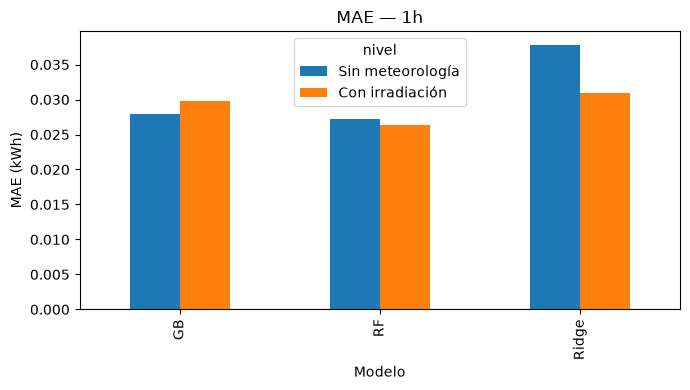

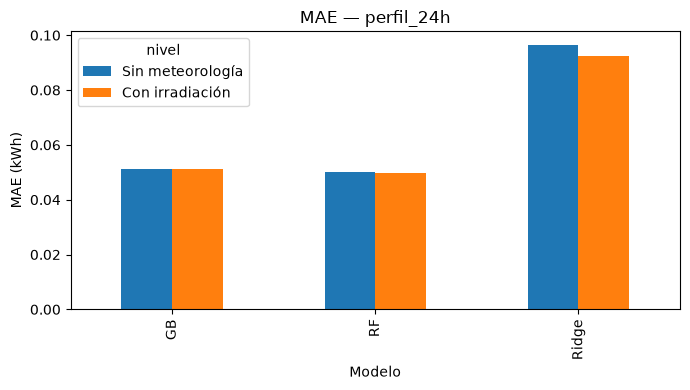

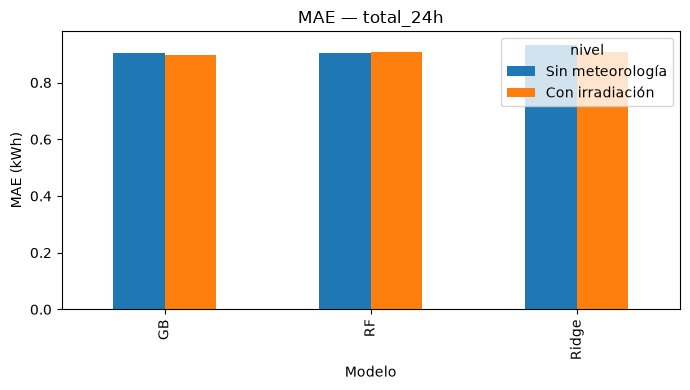

Recordatorio: el test de 2020 es conocido; CAMS no acredita disponibilidad inmediata.
El nivel 3 solo estará completo con pronósticos realmente publicados antes de emitir.


In [9]:
for nombre_objetivo in tabla.index.get_level_values("objetivo").unique():
    ax = tabla.loc[nombre_objetivo, ["Sin meteorología", "Con irradiación"]].plot.bar(
        figsize=(7, 4), title=f"MAE — {nombre_objetivo}"
    )
    ax.set_ylabel("MAE (kWh)")
    ax.set_xlabel("Modelo")
    plt.tight_layout()
    plt.show()

print("Recordatorio: el test de 2020 es conocido; CAMS no acredita disponibilidad inmediata.")
print("El nivel 3 solo estará completo con pronósticos realmente publicados antes de emitir.")